# 조회 쿼리 · 담당: 양재훈

| 파트 | 내용 | 필요한 테이블 |
|---|---|---|
| A. 공공 데이터 분석 | 1 출원인 점유율 · 2 공동출원 · 3 IPC 분포 · 4 출원 추이 | patent 등 4개 (완성) |
| B. 특허 탐색 | 5 동의어 검색 · 6 후보 추천 | + search_term, criterion, candidate |
| C. 업무 현황 | 7 프로젝트 진행률 · 8 검토자별 할 일 · 9 확정을 막는 후보 · 10 결론 경로 | + 업무 테이블 |

**집계 원칙** (업무 규칙 최종안)
- 최종 결론(채택·제외)은 `candidate.final_conclusion` 기준으로,
- 판정(○/△/X)과 검토 결론은 `review.status = 'SUBMITTED'`인 것만 셈
- 1차와 2차는 `review.round`로 구분

**DB 선택:** `USE_MOCK = True`면 `make_mock_db.py`로 만든 **시험용 DB(가짜 검토 데이터)** 사용
- 업무 테이블 열 이름은 '트리거 설계안.txt' 기준의 가정 스키마 
- 건희님 최종 테이블이 나오면 `False`로 바꿔 실제 DB로 실행


## DB 연결

In [41]:
import sqlite3, os
import pandas as pd
pd.set_option('display.max_colwidth', 50)

USE_MOCK = True                     # 실제 업무 테이블이 생기면 False
DB = 'patent_mock.db' if USE_MOCK else 'patent_final.db'
assert os.path.exists(DB), f'{DB}가 없습니다.'
con = sqlite3.connect(f'file:{DB}?mode=ro', uri=True)   # 읽기 전용: 이 노트북은 DB를 바꾸지 않음
con.execute('PRAGMA foreign_keys = ON')

def q(sql, params=()):
    return pd.read_sql_query(sql, con, params=params)

def has(table):
    return con.execute("SELECT 1 FROM sqlite_master WHERE type='table' AND name=?", (table,)).fetchone() is not None

BIZ = all(has(t) for t in ['project', 'criterion', 'search_term', 'candidate', 'candidate_reviewer', 'review', 'review_item', 'team_member'])
TOTAL = con.execute('SELECT COUNT(*) FROM patent').fetchone()[0]

def qb(sql, params=()):
    """업무 테이블이 있을 때만 실행"""
    if not BIZ:
        print('업무 테이블이 아직 없어 건너뜀'); return None
    return q(sql, params)

print('DB:', DB, '/ 특허', TOTAL, '건 / 업무 테이블', '있음' if BIZ else '없음')
if USE_MOCK:
    print('※ 시험용 DB: B~E 파트의 검토 관련 숫자는 가짜 데이터라 보고서에 쓰면 안 됨.')

DB: patent_mock.db / 특허 3122 건 / 업무 테이블 있음
※ 시험용 DB: B~E 파트의 검토 관련 숫자는 가짜 데이터라 보고서에 쓰면 안 됨.


# A. 공공 데이터 분석

## 1. 출원인 점유율
- 출원인은 `applicant_id`가 아니라 **`name_norm`(주소 제거 이름)** 으로 묶음. (같은 기관이 주소만 달라 표기가 여러 개일 수 있기 때문)
- **전체 계수**(`n_patents`): 공동출원 특허를 참여 출원인 모두에게 1건씩 세고, 분모가 전체 특허 수라서 점유율 합이 100%를 넘음
- **분할 계수**(`frac`): 출원인이 k명인 특허를 1/k건씩 나눠 세고, 합이 정확히 전체 특허 수(100% : 3,122건)가 됨

In [42]:
q('''
WITH pa_k AS (                       -- 특허마다 (정규화) 출원인 수 k
  SELECT pa.patent_id, a.name_norm,
         COUNT(*) OVER (PARTITION BY pa.patent_id) AS k
  FROM patent_applicant pa JOIN applicant a USING (applicant_id)
),
per AS (
  SELECT name_norm,
         COUNT(DISTINCT patent_id) AS n_patents,
         SUM(1.0 / k)              AS frac
  FROM pa_k GROUP BY name_norm
)
SELECT RANK() OVER (ORDER BY n_patents DESC)             AS rnk,
       name_norm,
       n_patents,
       ROUND(100.0 * n_patents / :total, 2)              AS share_pct,
       ROUND(frac, 1)                                    AS frac,
       ROUND(100.0 * frac / :total, 2)                   AS frac_share_pct
FROM per
ORDER BY n_patents DESC
LIMIT 15
''', {'total': TOTAL})

,rnk,name_norm,n_patents,share_pct,frac,frac_share_pct
0,1,삼성전자주식회사,200,6.41,191.0,6.12
1,2,한국전자통신연구원,123,3.94,119.0,3.81
2,3,퀄컴 인코포레이티드,104,3.33,104.0,3.33
3,4,구글 엘엘씨,99,3.17,99.0,3.17
4,5,엘지전자 주식회사,64,2.05,63.0,2.02
5,6,현대자동차주식회사,50,1.60,45.5,1.46
6,7,한국과학기술원,48,1.54,43.0,1.38
7,8,연세대학교 산학협력단,44,1.41,39.2,1.25
8,9,"마이크로소프트 테크놀로지 라이센싱, 엘엘씨",37,1.19,37.0,1.19
9,10,크루셜텍(주),36,1.15,29.2,0.93


In [43]:
# 검산: 분할 계수 합 = 전체 특허 수
q('''
SELECT ROUND(SUM(1.0 / k), 6) AS frac_sum, :total AS total
FROM (SELECT COUNT(*) OVER (PARTITION BY patent_id) AS k FROM patent_applicant)
''', {'total': TOTAL})

,frac_sum,total
0,3122.0,3122


## 2. 공동출원
### 2-1. 공동출원 현황

In [44]:
q('''
WITH k AS (SELECT patent_id, COUNT(*) AS n_app FROM patent_applicant GROUP BY patent_id)
SELECT n_app AS 출원인수, COUNT(*) AS 특허수,
       ROUND(100.0 * COUNT(*) / :total, 2) AS pct
FROM k GROUP BY n_app ORDER BY n_app
''', {'total': TOTAL})

,출원인수,특허수,pct
0,1,2902,92.95
1,2,183,5.86
2,3,22,0.70
3,4,11,0.35
4,5,2,0.06
5,6,2,0.06


### 2-2. 공동출원 쌍 Top 15
- 같은 특허를 함께 낸 출원인 두 명을 **self-join**으로 짝짓기
- `a1.name_norm < a2.name_norm` 조건으로 (A,B)와 (B,A)가 두 번 나오지 않게 하고, 같은 기관끼리의 짝도 제외

In [45]:
q('''
SELECT a1.name_norm AS 출원인1, a2.name_norm AS 출원인2,
       COUNT(DISTINCT p1.patent_id) AS 공동출원수
FROM patent_applicant p1
JOIN patent_applicant p2 ON p1.patent_id = p2.patent_id
JOIN applicant a1 ON a1.applicant_id = p1.applicant_id
JOIN applicant a2 ON a2.applicant_id = p2.applicant_id
WHERE a1.name_norm < a2.name_norm
GROUP BY a1.name_norm, a2.name_norm
ORDER BY 공동출원수 DESC, 출원인1
LIMIT 15
''')

,출원인1,출원인2,공동출원수
0,레이저세미콘 주식회사,크루셜텍(주),13
1,기아 주식회사,현대자동차주식회사,7
2,삼성전자주식회사,우니페르지타에트 취리히,5
3,전남대학교산학협력단,주식회사 셀바스에이아이,4
4,주식회사 디아이랩,한국도로공사,4
5,렉스젠(주),안순현,3
6,삼성전자주식회사,서울대학교산학협력단,3
7,송원호,제일정보통신(주),3
8,수원대학교산학협력단,위아코퍼레이션 주식회사,3
9,연세대학교 산학협력단,한국전자통신연구원,3


## 3. IPC 분포
### 3-1. 서브클래스(앞 4자리)별 특허 수 Top 10
- 특허 1건에 IPC가 여러 개라서 `COUNT(*)`가 아닌 `COUNT(DISTINCT patent_id)` 사용
- 검색식이 G06N·G06V지만 함께 붙은 G06F·G06T 같은 분류도 나옴

In [46]:
q('''
SELECT ipc_subclass,
       COUNT(DISTINCT patent_id)                         AS 특허수,
       ROUND(100.0 * COUNT(DISTINCT patent_id) / :total, 1) AS pct
FROM patent_ipc
GROUP BY ipc_subclass
ORDER BY 특허수 DESC
LIMIT 10
''', {'total': TOTAL})

,ipc_subclass,특허수,pct
0,G06V,2129,68.2
1,G06F,1251,40.1
2,G06N,1135,36.4
3,G06T,550,17.6
4,G06Q,531,17.0
5,H04N,437,14.0
6,G06K,190,6.1
7,H04L,164,5.3
8,G08G,149,4.8
9,H04W,141,4.5


## 4. 출원 추이 
### (보조 조회 · 최종적으로 기술동향 설명이 필요할 때만 사용)
### 4-1. 월별 출원 수


In [47]:
monthly = q('''
SELECT strftime('%Y-%m', application_date) AS ym, COUNT(*) AS 출원수
FROM patent
GROUP BY ym ORDER BY ym
''')
print(len(monthly), '개월')
monthly.head(12)

36 개월


,ym,출원수
0,2014-01,64
1,2014-02,82
2,2014-03,66
3,2014-04,39
4,2014-05,71
5,2014-06,52
6,2014-07,57
7,2014-08,46
8,2014-09,48
9,2014-10,61


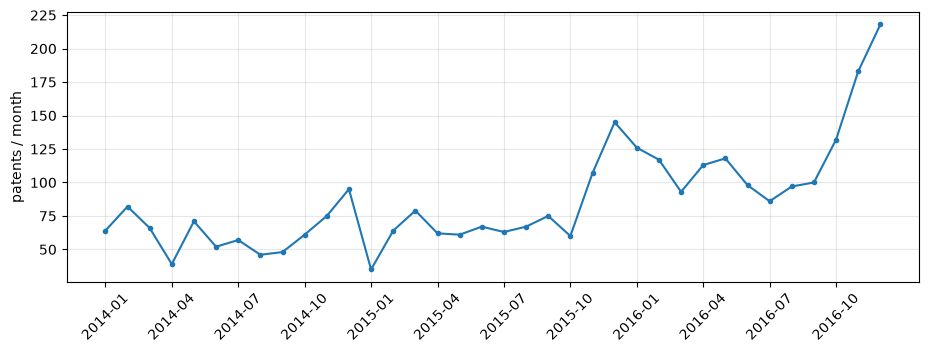

In [48]:
ax = monthly.plot(x='ym', y='출원수', figsize=(11, 3.5), legend=False, marker='o', ms=3)
ax.set_xlabel(''); ax.set_ylabel('patents / month')
ax.set_xticks(range(0, len(monthly), 3)); ax.set_xticklabels(monthly['ym'][::3], rotation=45)
ax.grid(alpha=.3)

### 4-2. 연도 × G06N/G06V

In [49]:
q('''
SELECT substr(p.application_date, 1, 4) AS 연도,
       COUNT(DISTINCT CASE WHEN i.ipc_subclass = 'G06N' THEN p.patent_id END) AS G06N,
       COUNT(DISTINCT CASE WHEN i.ipc_subclass = 'G06V' THEN p.patent_id END) AS G06V,
       COUNT(DISTINCT p.patent_id)                                            AS 전체
FROM patent p JOIN patent_ipc i USING (patent_id)
GROUP BY 연도 ORDER BY 연도
''')

,연도,G06N,G06V,전체
0,2014,163,609,756
1,2015,267,656,885
2,2016,705,864,1481


# B. 특허 탐색
### 5,6번 항목에서 사용하는 열은 '트리거_설계안.txt'에서 일부 열 만 사용
## 5. 동의어 검색
- 비교요소마다 `search_term`에 등록한 검색어를 `LIKE '%' || term || '%'`로 JOIN해서 찾음
- 한 특허가 여러 검색어에 걸려도 `GROUP BY patent_id`로 1건으로 간주
- 검색 범위는 국문 명칭, 영문 명칭, 요약. 영문 명칭까지 넣으면 `neural` 같은 영어 검색어가 많이 걸림(팀 결정 필요).
- 업무 테이블이 없으면 아래 `TERMS` 예시로 만든 TEMP 테이블을 대신 사용

In [50]:
if has('search_term'):
    TERM_SRC = '''SELECT c.project_id, t.criterion_id, t.term
                  FROM search_term t JOIN criterion c USING (criterion_id)'''
else:
    TERMS = {1: ['신경망', '뉴럴', 'neural', '딥러닝', '딥 러닝', '심층 학습'],
             2: ['얼굴 인식', '안면 인식', '얼굴 검출', 'face recognition']}
    con.execute('CREATE TEMP TABLE IF NOT EXISTS tmp_term (criterion_id INTEGER, term TEXT)')
    con.execute('DELETE FROM tmp_term')
    con.executemany('INSERT INTO tmp_term VALUES (?,?)', [(c, t) for c, ts in TERMS.items() for t in ts])
    TERM_SRC = 'SELECT 1 AS project_id, criterion_id, term FROM temp.tmp_term'

MATCH = '''(p.title_ko LIKE '%' || t.term || '%'
         OR p.title_en LIKE '%' || t.term || '%'
         OR p.abstract LIKE '%' || t.term || '%')'''
q(f'SELECT * FROM ({TERM_SRC}) LIMIT 8')

,project_id,criterion_id,term
0,1,1,얼굴 인식
1,1,1,안면 인식
2,1,1,얼굴 검출
3,1,1,face
4,1,2,합성곱
5,1,2,컨볼루션
6,1,2,CNN
7,1,2,신경망


### 5-1. 비교요소 하나의 검색어별 적중 수와 동의어 효과

In [51]:
CRIT = con.execute(f'SELECT MIN(criterion_id) FROM ({TERM_SRC})').fetchone()[0]   # 시험할 비교요소
per_term = q(f'''
SELECT t.term, COUNT(p.patent_id) AS 적중
FROM ({TERM_SRC}) t LEFT JOIN patent p ON {MATCH}
WHERE t.criterion_id = :c
GROUP BY t.term ORDER BY 적중 DESC
''', {'c': CRIT})
union_n = q(f'''
SELECT COUNT(DISTINCT p.patent_id) AS n
FROM patent p JOIN ({TERM_SRC}) t ON {MATCH}
WHERE t.criterion_id = :c
''', {'c': CRIT}).n.item()
top = per_term.iloc[0]
print(f"가장 많이 걸린 검색어 '{top.term}' {top.적중}건 → 동의어 합집합 {union_n}건 (+{100*(union_n-top.적중)/top.적중:.0f}%)")
per_term

가장 많이 걸린 검색어 'face' 128건 → 동의어 합집합 140건 (+9%)


,term,적중
0,face,128
1,얼굴 인식,43
2,얼굴 검출,13
3,안면 인식,4


### 5-2. 기간·출원인·IPC 조건을 함께 건 검색
- 조건을 `None`으로 두면 그 조건은 적용 X
- 날짜·출원인·IPC 조건은 인덱스를 쓸 수 있지만 `LIKE '%…%'`는 인덱스를 쓰지 못 함

In [52]:
def search(criterion_id, date_from=None, date_to=None, applicant=None, subclass=None, limit=10):
    return q(f'''
    SELECT p.application_no, p.title_ko, p.application_date, p.cited_count,
           GROUP_CONCAT(DISTINCT t.term) AS 적중_검색어
    FROM patent p JOIN ({TERM_SRC}) t ON {MATCH}
    WHERE t.criterion_id = :c
      AND (:f IS NULL OR p.application_date >= :f)
      AND (:t IS NULL OR p.application_date <= :t)
      AND (:a IS NULL OR EXISTS (SELECT 1 FROM patent_applicant pa JOIN applicant a USING (applicant_id)
                                 WHERE pa.patent_id = p.patent_id AND a.name_norm LIKE '%' || :a || '%'))
      AND (:s IS NULL OR EXISTS (SELECT 1 FROM patent_ipc i
                                 WHERE i.patent_id = p.patent_id AND i.ipc_subclass = :s))
    GROUP BY p.patent_id
    ORDER BY p.application_date
    LIMIT :lim
    ''', {'c': criterion_id, 'f': date_from, 't': date_to, 'a': applicant, 's': subclass, 'lim': limit})

search(CRIT, date_from='2016-01-01', subclass='G06V')

,application_no,title_ko,application_date,cited_count,적중_검색어
0,1020160001244,관상학적 특징 정보를 이용한 얼굴인식 장치 및 방법,2016-01-05,NaN,"face,얼굴 인식"
1,1020160001249,신원 인식 장치 및 방법,2016-01-05,4.0,얼굴 인식
2,1020177025207,T1 MRI로부터의 자동 3D 분할 및 피질 표면 재구성,2016-01-18,1.0,face
3,1020160008964,얼굴 검출 장치 및 방법,2016-01-25,1.0,"face,얼굴 검출"
4,1020207013827,얼굴 생체 내 검출 방법 및 장치,2016-01-25,NaN,"face,얼굴 검출"
5,1020177023967,얼굴 생체 내 검출 방법 및 장치,2016-01-25,NaN,"face,얼굴 검출"
6,1020227004804,결제를 위한 사용자 인터페이스,2016-01-28,NaN,face
7,1020217030343,결제를 위한 사용자 인터페이스,2016-01-28,NaN,face
8,1020187019643,결제를 위한 사용자 인터페이스,2016-01-28,NaN,face
9,1020207010007,결제를 위한 사용자 인터페이스,2016-01-28,NaN,face


## 6. 후보 추천 (프로젝트별)
- 프로젝트의 비교요소 4개 검색어를 모두 써서, **걸린 비교요소 수가 많은 특허**부터 추천
- 정렬 기준 : 적중한 비교요소 -> 피인용 수 -> 적중한 검색어 수 -> 출원일 순 
- **이미 그 프로젝트 후보로 등록된 특허는 제외* (`NOT EXISTS`, 규칙 2와 같은 기준).

In [53]:
EXCLUDE = '''AND NOT EXISTS (SELECT 1 FROM candidate c
                             WHERE c.project_id = h.project_id AND c.patent_id = h.patent_id)''' if has('candidate') else ''

def recommend(project_id, limit=10):
    return q(f'''
    WITH h AS (
      SELECT t.project_id, p.patent_id,
             COUNT(DISTINCT t.criterion_id) AS 적중_요소수,
             COUNT(DISTINCT t.term)         AS 적중_검색어수
      FROM patent p JOIN ({TERM_SRC}) t ON {MATCH}
      WHERE t.project_id = :pid
      GROUP BY t.project_id, p.patent_id
    )
    SELECT p.application_no, p.title_ko, p.application_date,
           h.적중_요소수, h.적중_검색어수, COALESCE(p.cited_count, 0) AS 피인용
    FROM h JOIN patent p USING (patent_id)
    WHERE 1 = 1 {EXCLUDE}
    ORDER BY h.적중_요소수 DESC, 피인용 DESC, h.적중_검색어수 DESC, p.application_date
    LIMIT :lim
    ''', {'pid': project_id, 'lim': limit})

recommend(1)

,application_no,title_ko,application_date,적중_요소수,적중_검색어수,피인용
0,1020150019467,얼굴 인식 및 화자 인식이 융합된 인증 방법,2015-02-09,4,5,8
1,1020140040374,얼굴 인식을 이용한 출입 통제 장치 및 방법,2014-04-04,3,4,3
2,1020160049385,다양한 컬러 공간에서 협동 얼굴 컬러 특징 학습 방법 및 장치,2016-04-22,3,3,3
3,1020150153203,다중확인 얼굴 인식 시스템 및 그 방법,2015-11-02,3,4,1
4,1020160096656,눈동자 추적 기반의 하르유사특징을 이용한 얼굴인증 방법,2016-07-29,3,4,1
5,1020140000255,얼굴 인식에 의한 출입관리장치 및 방법,2014-01-02,3,3,1
6,1020150169441,인터벌 타입-2 RBF 신경회로망 기반 CT 기법을 이용한 강인한 얼굴 인식 패턴 ...,2015-11-30,3,4,0
7,1020150028199,안면인식을 이용한 병원 관리시스템 및 관리 방법,2015-02-27,2,3,17
8,1020140067122,안면인식과 태그인식을 이용하여 접근자의 신분확인 및 동선추적이 가능한 제한구역 출입...,2014-06-02,2,2,11
9,1020150155530,비대면 실명확인 온라인 신분증 식별 및 인식 시스템 및 방법,2015-11-06,2,2,9


# C. 업무 현황 

## 7. 프로젝트 진행률
- 후보 상태별 건수와 최종 결론(`final_conclusion`) 건수를 셈
- **1차 제출률** = 제출된 1차 검토 수 ÷ (후보 수 × 2)
- **결론률** = 최종 결론이 난 후보 ÷ 전체 후보
- 후보 집계와 검토 집계를 CTE로 따로 낸 뒤 합침 한 번에 JOIN하면 검토 행 수만큼 후보가 중복으로 셈

In [54]:
qb('''
WITH cand AS (
  SELECT project_id,
         COUNT(*)                                  AS 후보,
         SUM(status = '미검토')                     AS 미검토,
         SUM(status = '검토중')                     AS 검토중,
         SUM(status = '재검토')                     AS 재검토,
         SUM(status = '담당자결정')                  AS 담당자결정,
         SUM(final_conclusion = '채택')             AS 채택,
         SUM(final_conclusion = '제외')             AS 제외,
         SUM(final_conclusion IS NOT NULL)         AS 결론
  FROM candidate GROUP BY project_id
),
rev AS (
  SELECT c.project_id, COUNT(*) AS 제출1차
  FROM review r JOIN candidate c USING (candidate_id)
  WHERE r.round = 1 AND r.status = 'SUBMITTED'
  GROUP BY c.project_id
)
SELECT p.project_id, p.title, m.name AS 담당자, p.status AS 상태,
       COALESCE(cand.후보, 0) AS 후보, cand.미검토, cand.검토중, cand.재검토, cand.담당자결정,
       cand.채택, cand.제외,
       ROUND(100.0 * COALESCE(rev.제출1차, 0) / NULLIF(2 * cand.후보, 0), 1) AS 제출률1차,
       ROUND(100.0 * cand.결론 / NULLIF(cand.후보, 0), 1)                    AS 결론률
FROM project p
JOIN team_member m ON m.member_id = p.owner_id
LEFT JOIN cand USING (project_id)
LEFT JOIN rev  USING (project_id)
ORDER BY p.project_id
''')

,project_id,title,담당자,상태,후보,미검토,검토중,재검토,담당자결정,채택,제외,제출률1차,결론률
0,1,마스크 착용 얼굴 인식,김연준,진행,10,1,0,1,0,2,6,90.0,80.0
1,2,운전자 졸음 감지,최재원,진행,10,0,2,2,1,2,3,90.0,50.0
2,3,필기 문자 인식,남건희,진행,10,2,0,3,0,1,4,80.0,50.0
3,4,불량 검사 자동화,양재훈,진행,10,1,1,3,1,1,3,85.0,40.0
4,5,보행자 행동 예측,박채연,진행,10,2,2,0,1,0,5,70.0,50.0


## 8. 검토자별 할 일
배정된 후보마다 이 검토자의 상태를 확인
- **1차 미작성**: 1차 검토 행이 아예 없음
- **1차 임시저장**: DRAFT 상태
- **2차 대기**: 후보가 '재검토' 상태인데 이 검토자의 2차 제출이 없음

In [55]:
qb('''
SELECT m.name AS 검토자,
       COUNT(*) AS 배정,
       SUM(EXISTS (SELECT 1 FROM review r WHERE r.candidate_id = cr.candidate_id AND r.member_id = cr.member_id
                   AND r.round = 1 AND r.status = 'SUBMITTED'))                                    AS 제출1차,
       SUM(EXISTS (SELECT 1 FROM review r WHERE r.candidate_id = cr.candidate_id AND r.member_id = cr.member_id
                   AND r.round = 1 AND r.status = 'DRAFT'))                                        AS 임시저장1차,
       SUM(NOT EXISTS (SELECT 1 FROM review r WHERE r.candidate_id = cr.candidate_id AND r.member_id = cr.member_id
                       AND r.round = 1))                                                           AS 미작성1차,
       SUM(c.status = '재검토' AND NOT EXISTS (
             SELECT 1 FROM review r WHERE r.candidate_id = cr.candidate_id AND r.member_id = cr.member_id
             AND r.round = 2 AND r.status = 'SUBMITTED'))                                          AS 대기2차
FROM candidate_reviewer cr
JOIN team_member m USING (member_id)
JOIN candidate c   USING (candidate_id)
GROUP BY m.member_id
ORDER BY m.member_id
''')

,검토자,배정,제출1차,임시저장1차,미작성1차,대기2차
0,김연준,19,17,0,2,7
1,최재원,20,17,1,2,1
2,남건희,20,13,3,4,2
3,양재훈,21,17,1,3,4
4,박채연,19,19,0,0,4


## 9. 확정을 막는 후보 (규칙 10)
- `trg_confirm_check`와 같은 조건. 트리거는 확정을 **거부만** 하므로, 담당자가 무엇을 처리해야 하는지 이 쿼리로 미리 보여줌
- 규치10 : 후보 없음·최종 결론 없는 후보·검토자 2명 미만 후보가 있으면 ‘확정’할 수 없고, 확정 후에는 수정할 수 없다.

In [56]:
qb('''
SELECT p.project_id, p.title, c.candidate_id, pt.application_no, c.status,
       COUNT(cr.member_id) AS 검토자수,
       CASE WHEN COUNT(cr.member_id) < 2       THEN '검토자 2명 미만'
            WHEN c.status = '담당자결정'          THEN '담당자 결정 필요'
            WHEN c.status = '재검토'             THEN '2차 검토 대기'
            ELSE '1차 검토 미완료' END            AS 사유
FROM candidate c
JOIN project p  USING (project_id)
JOIN patent pt  ON pt.patent_id = c.patent_id
LEFT JOIN candidate_reviewer cr USING (candidate_id)
GROUP BY c.candidate_id
HAVING c.final_conclusion IS NULL OR COUNT(cr.member_id) < 2
ORDER BY p.project_id, 사유
''')

,project_id,title,candidate_id,application_no,status,검토자수,사유
0,1,마스크 착용 얼굴 인식,10,1020140043841,미검토,2,1차 검토 미완료
1,1,마스크 착용 얼굴 인식,3,1020140191661,재검토,2,2차 검토 대기
2,2,운전자 졸음 감지,11,1020160177527,검토중,2,1차 검토 미완료
3,2,운전자 졸음 감지,20,1020150023379,검토중,2,1차 검토 미완료
4,2,운전자 졸음 감지,16,1020150014061,재검토,2,2차 검토 대기
5,2,운전자 졸음 감지,18,1020140038918,재검토,2,2차 검토 대기
6,2,운전자 졸음 감지,13,1020167001038,담당자결정,2,담당자 결정 필요
7,3,필기 문자 인식,29,1020160050703,미검토,2,1차 검토 미완료
8,3,필기 문자 인식,23,1020140011485,재검토,2,2차 검토 대기
9,3,필기 문자 인식,27,1020160142974,재검토,2,2차 검토 대기


## 10. 최종 결론이 난 경로
- 후보의 최종 결론이 1차 합의, 2차 합의, 담당자 결정 중 어디서 정해졌는지 셈
- 담당자 결정 비율이 높으면 판정 기준이 잘 안 맞는다는 뜻
- 순번 라벨 : 1차 합의는 1번, 2차 합의는 2번, 담당자 결정은 3번 

In [57]:
qb('''
SELECT p.title,
       CASE WHEN c.decided_by IS NOT NULL THEN '3 담당자 결정'
            WHEN EXISTS (SELECT 1 FROM review r WHERE r.candidate_id = c.candidate_id
                         AND r.round = 2 AND r.status = 'SUBMITTED') THEN '2 2차 합의'
            ELSE '1 1차 합의' END AS 경로,
       SUM(c.final_conclusion = '채택') AS 채택,
       SUM(c.final_conclusion = '제외') AS 제외
FROM candidate c JOIN project p USING (project_id)
WHERE c.final_conclusion IS NOT NULL
GROUP BY p.project_id, 경로
ORDER BY p.project_id, 경로
''')

,title,경로,채택,제외
0,마스크 착용 얼굴 인식,1 1차 합의,1,3
1,마스크 착용 얼굴 인식,2 2차 합의,1,1
2,마스크 착용 얼굴 인식,3 담당자 결정,0,2
3,운전자 졸음 감지,1 1차 합의,0,1
4,운전자 졸음 감지,2 2차 합의,2,1
5,운전자 졸음 감지,3 담당자 결정,0,1
6,필기 문자 인식,1 1차 합의,0,2
7,필기 문자 인식,2 2차 합의,0,1
8,필기 문자 인식,3 담당자 결정,1,1
9,불량 검사 자동화,1 1차 합의,0,2


In [58]:
con.close()